# Aufgabe 1 Euler

In [20]:
#b)
#a ist später weil man für die params erstmal die function sehen sollte


import numpy as np
#import numpy weil das noch nciht importiert war

def EulerExpl(func,pars,h,func_init,tend):
    #definition der euler function und welche params übergeben werden (merh zu den params unten)
    tvals = np.linspace(0,tend,int(np.ceil(tend/h)+1))
    #die values für die t achse erstellt, weil wir ja für jeden schritt h von t=0 bis t= tend einen t value brauchen
    funcvals = np.zeros(len(tvals))
    #leeres array wird erstellt mit länge der t values, weil wir dafür ja die function variabelen berechnen wollen 
    old_val = func_init
    #alte value wird auf den anfangswert gesetzt
    funcvals[0] = old_val
    #dieser anfangwert wird als erste lösung in Funktionen werte gespeichert, weiul das ja bei t=0 ist
    for step in np.arange(1,len(tvals)):
        #schleife die unser array an zeitschritten durchgeht. Es wird ab index 1 angefangen, also dem 2 wert, weil wert 1 ja unserer startwert ist.und die schleife endet bei tend, also unserem endpunkt
        t_now = tvals[step]
        #jetzigen t wert nehmen wo wir gerade sind
        funcvals[step] = old_val+h*func(t_now,old_val,*pars)
        #berechne den wert unserer function mit altem wert + h mal ableitung, also basically da passioert die euler function
        #dieser wert wird bei dem gleichen index wie von unserem t values in function values gespeichert
        old_val = funcvals[step]
        #dieser wert wir dunser neuer alterwert
    return (tvals,funcvals)
    #ausgabe von unseren t und function arrays


a)

Parameter beschreibung:

func ist der Parameter für die Berechnug der Ableitung der Funktion. Es wird eine Funktion übergeben mit der die Ableitung berechnet werden kann, zb so etwas:
def func(t, y):
    return -2*y
Also häufig der rechte Teil einer DGL.

pars sind die Parameter die für diese function benötigt werden. deswegen werden sie in der euler funktion auch nur in der func method später entpackt udn genutzt. 

h ist die Schrittweite der Funktion. Also je kleiner h, desto kleinschrittiger wird die Annöherung und desto genauer wird das Ergebnis. Also die sprungweite für die t-Achse sozusagen.

func_init ist die initialisieruzng der function. Der Startwert der gesuchten funktion für t=0 wird übergeben zB bei f(0)=1 wird func_init = 1 überegeben. 

tend ist der endpunkt auf der t achse bei dem die euler berechnung stoppen soll. Bei tend =5 würde die euler funktion also von t=0 bis t =5 gehen mit den schritten h. 



# Aufgabe 2

a) und b)

![Aufgabe 2ab](A2ab.png)



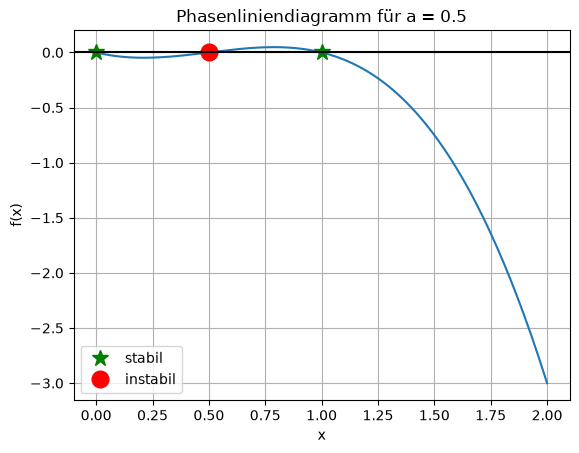

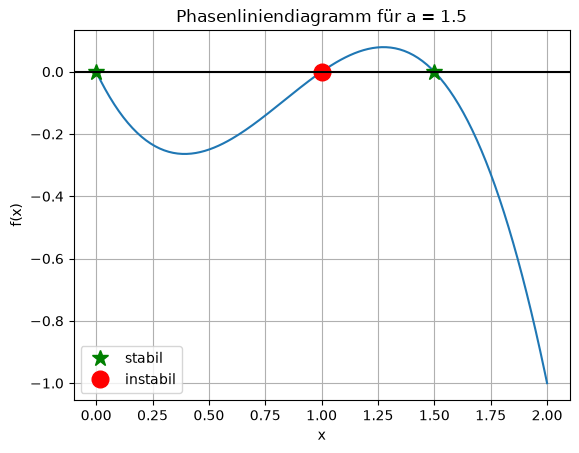

In [21]:
#c Phasenliniendiagramm

#imports
import numpy as np
import matplotlib.pyplot as plt

#our DGL 
def f(t,x, a):
    #t nehme ihc mit, damit ich die bei euler nutzen kann
    return x * (1 - x) * (x - a)

#define x values von 0-2
x = np.linspace(0, 2, 200)

#do it for both a
for a in [0.5, 1.5]:
    #create plot
    plt.figure()
    #plot function
    plt.plot(x, f(0,x, a))

    #r is red, g is green, * is star and o ist point
    #aus der analyse aus a und bi wissen wir die equilibria an 0,1 und a 
    #wir haben also immer bei 0, bei 1 und dann bei 0,5 und einmal bei 1,5
    #stabilität sieht man aus b für jeweiligen a
    if a == 0.5:
        #plotte equilibria für a=0,5
        plt.plot([0, 1], [0, 0], "g*",markersize =12, label="stabil")
        plt.plot(0.5, 0, "ro",markersize =12, label="instabil")
    else:
        #plotte equilibria für a=1,5
        plt.plot([0, 1.5], [0, 0], "g*",markersize =12, label="stabil")
        plt.plot(1, 0, "ro",markersize =12, label="instabil")

    #plotte 0 linie weil die equilibria darauf liegen sollen
    plt.axhline(0, color="black")
    #formschönheit
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.title(f"Phasenliniendiagramm für a = {a}")
    plt.legend()
    plt.grid()
    plt.show()

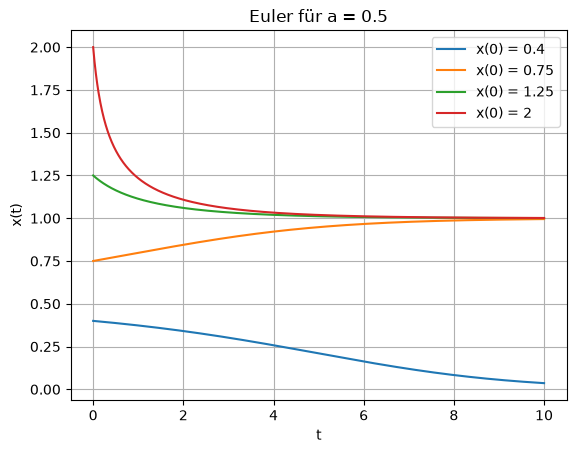

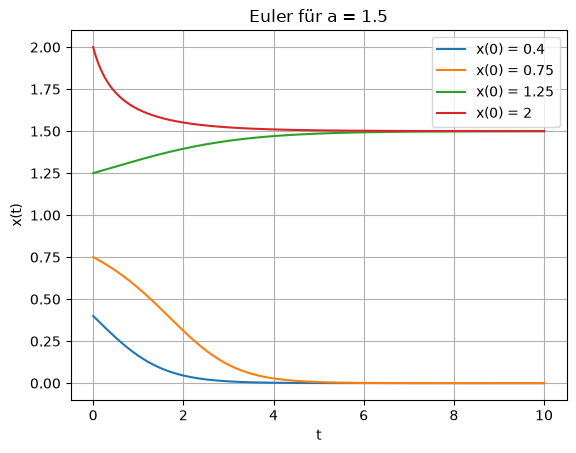

In [22]:
#d

#startbedingungen
x_starts = [0.4, 0.75, 1.25, 2]
#schrittweite
h = 0.01

#für jedes a soll das gemacht werden, weil wir mehrere a gegeben haben
for a in [0.5, 1.5]:
    #erstelle ein plot für jedes a
    plt.figure()

    for x0 in x_starts:
        #mache euler für jede startbedingung und bis t_end =10, die euler funktion fängt eh bei 0 an
        t, x = EulerExpl(f, (a,), h, x0, 10)
        #plotte die lösung
        plt.plot(t, x, label=f"x(0) = {x0}")
    #zeige den plot für jedes a
    plt.xlabel("t")
    plt.ylabel("x(t)")
    plt.title(f"Euler für a = {a}")
    plt.legend()
    plt.grid()
    plt.show()

e)

Man sieht, dass die Graphen mit unterschiedlichen Anfangsbedingungen gegen unterschiedliche stabile equilibria konvergieren. bei a=0,5 ist das 1 und 0, während bei a=1,5 es gegen 0 und 1,5 konvergiert. Diese 4 sind alle unseren stabilen equilibria. Je nachdem welches Equilibrium an welchem startwert näher lag, gegen den konvergiert es. 

Die DGL istn also bistable, bedeutet sie aht zwei stabile punkte zu denen sie konvergieren kann 